## Predicting Hospital Readmission of Diabetic Patients

**Author:** Suryansh Mishra ([GitHub](https://github.com/Suryansh2111))


The purpose of this project is to predict the possibility of hospital readmission of a diabetic patient. A hospital readmission is when a patient is discharged from the hospital and get readmitted in certain period of a time for a similar diagnosis. Hospital readmission for certain digit is considered to be the measure of the quality of hospitals. So to regulate this, prediction of hospital readmission will help to take appropriate measures in medication. The hospital readmission is predicted based on other factors in a dataset.

### Dataset:

For this project, the dataset is taken from UCI Machine Learning Repository. The dataset is publicly available to download from: https://archive.ics.uci.edu/ml/datasets/diabetes+130-us+hospitals+for+years+1999-2008#

The dataset consist of 50 features and 101766 records.

The target variable has 3 classes and this is the multi-class classification problem.

The data set is easy to understand.However, the meaning of some of the column headers are not obvious. Here's what they mean:

###### Encounter ID : Unique identifier of an encounter	
###### Patient number : Unique identifier of a patient	
###### Race : Caucasian, Asian, African American, Hispanic, and other	
###### Gender: male, female	
###### Age : Grouped in 10-year intervals: 0, 10), 10, 20), …, 90, 100)	
###### Weight : Weight in pounds.	
###### Admission type :identifier corresponding to 9 distinct values, for example, emergency, urgent, elective, newborn, and not available	
###### Discharge disposition: Integer identifier corresponding to 29 distinct values, for example, discharged to home, expired, and not available	
###### Admission source : Integer identifier corresponding to 21 distinct values, for example, physician referral, emergency room, and transfer from a hospital
###### Time in hospital : number of days between admission and discharge	
###### Payer code : Integer identifier corresponding to 23 distinct values, for example, Blue Cross/Blue Shield, Medicare, and self-pay	
###### Medical specialty : Integer identifier of a specialty of the admitting physician, corresponding to 84 distinct values, for example, cardiology, internal medicine, family/general practice, and surgeon	
###### Number of lab procedures : Number of lab tests performed during the encounter
###### Number of procedures : Number of procedures (other than lab tests) performed during the encounter
###### Number of medications :	Number of distinct generic names administered during the encounter
###### Number of outpatient visits : Number of outpatient visits of the patient in the year preceding the encounter	
###### Number of emergency visits : Number of emergency visits of the patient in the year preceding the encounter	
###### Number of inpatient visits : Number of inpatient visits of the patient in the year preceding the encounter	
###### Diagnosis 1	: The primary diagnosis (coded as first three digits of ICD9)
###### Diagnosis 2	: Secondary diagnosis (coded as first three digits of ICD9)
###### Diagnosis 3	: Additional secondary diagnosis (coded as first three digits of ICD9)
###### Number of diagnoses : Number of diagnoses entered to the system	
###### Glucose serum test result :Indicates the range of the result or if the test was not taken. Values: “>200,” “>300,” “normal,” and “none” if not measured	
###### A1c test result	: Indicates the range of the result or if the test was not taken. Values: “>8” if the result was greater than 8%, “>7” if the result was greater than 7% but less than 8%, “normal” if the result was less than 7%, and “none” if not measured.	
###### Change of medications :	Indicates if there was a change in diabetic medications (either dosage or generic name). Values: “change” and “no change”	0%
###### Diabetes medications : Indicates if there was any diabetic medication prescribed. Values: “yes” and “no”	0%
###### 24 features for medications	Nominal	For the generic names: metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, sitagliptin, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, and metformin-pioglitazone :           
###### - the feature indicates whether the drug was prescribed or there was a change in the dosage. Values: “up” if the dosage was increased during the encounter, “down” if the dosage was decreased, “steady” if the dosage did not change, and “no” if the drug was not prescribed	
###### Readmitted :Days to inpatient readmission. Values: “<30” if the patient was readmitted in less than 30 days, “>30” if the patient was readmitted in more than 30 days, and “No” for no record of readmission. (Target Variable)








In [1]:
#Importing Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

from statistics import mode
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [2]:
#Importing data

dataframe= pd.read_csv("diabetic_data.csv")
dataframe.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
#Identifying Shape

dataframe.shape

(101766, 50)

In [4]:
#Identifying Column

dataframe.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

In [5]:
#information of data set

dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [6]:
#Statistical description of data
dataframe.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [7]:
#Identifying Null Values
dataframe.isna().sum()

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

Text(0.5, 1.0, 'Null Values')

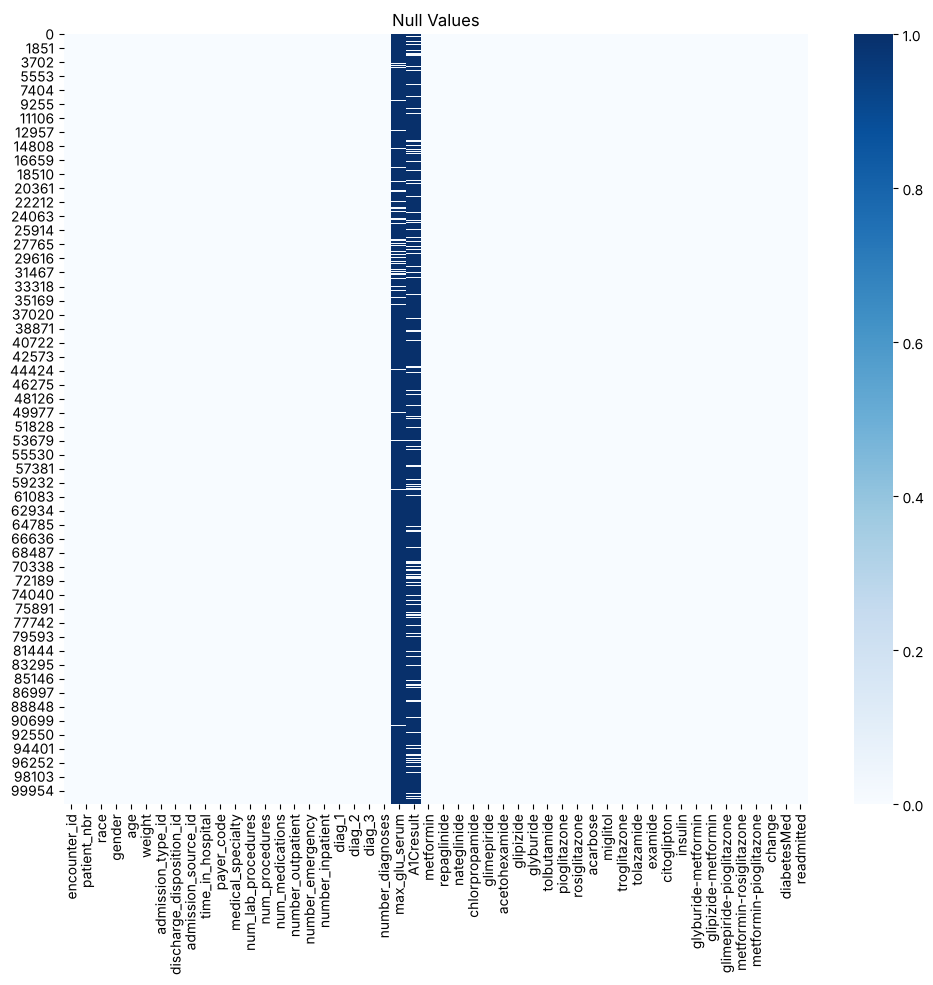

In [8]:
#Graphical visualization of missing values

plt.figure(figsize=(12,10))
ax = plt.axes()

sb.heatmap(dataframe.isnull(),cmap = "Blues")

ax.set_title("Null Values")

In [9]:
#Identifying corrupted values
for col in dataframe.columns:
    if dataframe[col].dtype == object:
         print(col,dataframe[col][dataframe[col] == '?'].count())

race 2273
gender 0
age 0
weight 98569
payer_code 40256
medical_specialty 49949
diag_1 21
diag_2 358
diag_3 1423
max_glu_serum 0
A1Cresult 0
metformin 0
repaglinide 0
nateglinide 0
chlorpropamide 0
glimepiride 0
acetohexamide 0
glipizide 0
glyburide 0
tolbutamide 0
pioglitazone 0
rosiglitazone 0
acarbose 0
miglitol 0
troglitazone 0
tolazamide 0
examide 0
citoglipton 0
insulin 0
glyburide-metformin 0
glipizide-metformin 0
glimepiride-pioglitazone 0
metformin-rosiglitazone 0
metformin-pioglitazone 0
change 0
diabetesMed 0
readmitted 0


### Data Cleaning

The above code showcase there are corrupted values.We need to handle this corrupted values before proceeding for predictions.


In [10]:
#creating a dataframe copy before pre-processing
df = dataframe.copy()
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [11]:
#Since More than 50% of data is corrupted in columns weight, prayer_code, and medical_specialty,
#we are dropping those columns
# dropping columns with too many missing values
df = df.drop(['weight', 'payer_code', 'medical_specialty'], axis = 1)

In [12]:
#There are 4 columns race, diag 1, diag 2 , diag 3 which have corrupted values less than 5%, 
#so we are not dropping columns.
#We are removing rows of the corrupted values of these columns

df = df[df.race != '?']
df = df[df.diag_1 != '?']
df = df[df.diag_2 != '?']
df = df[df.diag_3 != '?']

In [13]:
# remove columns having same value in each row: citoglipton, examide
#These columns have same values for each row, So these cannot provide any information for predicting readmission
df = df.drop(['citoglipton', 'examide'], axis = 1)

In [14]:
#identifying missing gender
print('gender', df['gender'][df['gender'] == 'Unknown/Invalid'].count())

gender 1


In [15]:
#Removing rows where gender is unknown
df = df[df.gender != 'Unknown/Invalid']


In [16]:
#After Clean up
print('gender', df['gender'][df['gender'] == 'Unknown/Invalid'].count())

gender 0


In [17]:
#identifying patients who are dead. 
print('discharge_disposition_id', df['discharge_disposition_id'][df['discharge_disposition_id'] == 11].count())

discharge_disposition_id 1606


In [18]:
#Removing dead patient as the probability of readmission is zero
df = df[df.discharge_disposition_id != 11]


In [19]:
#Checking Corrupted Values, once data is cleaned.
for col in df.columns:
    if df[col].dtype == object:
         print(col,df[col][df[col] == '?'].count())

race 0
gender 0
age 0
diag_1 0
diag_2 0
diag_3 0
max_glu_serum 0
A1Cresult 0
metformin 0
repaglinide 0
nateglinide 0
chlorpropamide 0
glimepiride 0
acetohexamide 0
glipizide 0
glyburide 0


tolbutamide 0
pioglitazone 0
rosiglitazone 0
acarbose 0
miglitol 0
troglitazone 0
tolazamide 0
insulin 0
glyburide-metformin 0
glipizide-metformin 0
glimepiride-pioglitazone 0
metformin-rosiglitazone 0
metformin-pioglitazone 0


change 0
diabetesMed 0
readmitted 0


In [20]:
#Finding Duplicate values

df.duplicated().sum()

np.int64(0)

Data is now clean and have no corrupted values.

In [21]:
#Shape of a new and reformed dataset
df.shape

(96446, 45)

### Data Preprocessing


There are some features which have same meaning but encoded differently. We are encoding these features into fewer categories

In [22]:
# re-encoding admission type, discharge type and admission source into fewer categories

df['admission_type_id'] = df['admission_type_id'].replace(2,1)
df['admission_type_id'] = df['admission_type_id'].replace(7,1)
df['admission_type_id'] = df['admission_type_id'].replace(6,5)
df['admission_type_id'] = df['admission_type_id'].replace(8,5)

df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(6,1)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(8,1)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(9,1)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(13,1)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(3,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(4,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(5,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(14,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(22,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(23,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(24,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(12,10)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(15,10)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(16,10)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(17,10)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(19,11)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(20,11)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(21,11)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(25,18)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(26,18)

df['admission_source_id'] = df['admission_source_id'].replace(2,1)
df['admission_source_id'] = df['admission_source_id'].replace(3,1)
df['admission_source_id'] = df['admission_source_id'].replace(5,4)
df['admission_source_id'] = df['admission_source_id'].replace(6,4)
df['admission_source_id'] = df['admission_source_id'].replace(10,4)
df['admission_source_id'] = df['admission_source_id'].replace(22,4)
df['admission_source_id'] = df['admission_source_id'].replace(25,4)
df['admission_source_id'] = df['admission_source_id'].replace(15,9)
df['admission_source_id'] = df['admission_source_id'].replace(17,9)
df['admission_source_id'] = df['admission_source_id'].replace(20,9)
df['admission_source_id'] = df['admission_source_id'].replace(21,9)
df['admission_source_id'] = df['admission_source_id'].replace(12,11)
df['admission_source_id'] = df['admission_source_id'].replace(13,11)
df['admission_source_id'] = df['admission_source_id'].replace(14,11)

After re-encoding, below are categories for each feature

Admission Type ID has below categories:

1. Emergency
2. Elective
3. Newborn
4. Not Available 

Discharge Disposition ID has below categories:

1. Discharged to home
2. Transfered to another short term hospital
3. Left AMA
4. Transfered to another hospital for aftercare.
5. Expired
6. Not Available
7. Transfered to federal health care facility
8. Transfered to psychatric hospital
9. Transfered to critical access hospital

Admission Source ID has below categories:

1. Referal
2. Transfer from a hospital
3. Emergency Room
4. Court/Law Enforcement
5. Not available
6. Baby
7. Transfer From Another Home Health Agency
8. Readmission to Same Home Health Agency
9. Born inside this hospital
10. Born outside this hospital
11. Transfer from Hospice


In [23]:
##creating patient visit as a new feature:
## It holds value of total number of visit of a patient in different cases

df['patient_visit'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']

As we know that Machine Learning model can only handle numerical features, so LabelEncoder, an in-built algorithm is used to convert categorical features into numerical features.

In [24]:
# Converting Categorical feature into numerical feature by using LabelEncoder

data_hospital = df.copy()


from sklearn.preprocessing import LabelEncoder

lb_encode = LabelEncoder()

data_hospital['race'] = lb_encode .fit_transform(data_hospital['race'])
print(lb_encode.classes_)
data_hospital['gender'] = lb_encode .fit_transform(data_hospital['gender'])
print(lb_encode.classes_)
data_hospital['age'] = lb_encode .fit_transform(data_hospital['age'])
print(lb_encode.classes_)
data_hospital['max_glu_serum'] = lb_encode .fit_transform(data_hospital['max_glu_serum'])
print(lb_encode.classes_)
data_hospital['A1Cresult'] = lb_encode.fit_transform(data_hospital['A1Cresult'])
print(lb_encode.classes_)
data_hospital['change'] = lb_encode .fit_transform(data_hospital['change'])
print(lb_encode.classes_)
data_hospital['diabetesMed'] = lb_encode.fit_transform(data_hospital['diabetesMed'])
print(lb_encode.classes_)



['AfricanAmerican' 'Asian' 'Caucasian' 'Hispanic' 'Other']
['Female' 'Male']
['[0-10)' '[10-20)' '[20-30)' '[30-40)' '[40-50)' '[50-60)' '[60-70)'
 '[70-80)' '[80-90)' '[90-100)']
['>200' '>300' 'Norm' nan]
['>7' '>8' 'Norm' nan]
['Ch' 'No']
['No' 'Yes']


In [25]:
data_hospital.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,patient_visit
1,149190,55629189,2,0,1,1,1,7,3,59,...,Up,No,No,No,No,No,0,1,>30,0
2,64410,86047875,0,0,2,1,1,7,2,11,...,No,No,No,No,No,No,1,1,NO,3
3,500364,82442376,2,1,3,1,1,7,2,44,...,Up,No,No,No,No,No,0,1,NO,0
4,16680,42519267,2,1,4,1,1,7,1,51,...,Steady,No,No,No,No,No,0,1,NO,0
5,35754,82637451,2,1,5,1,1,1,3,31,...,Steady,No,No,No,No,No,1,1,>30,0


In [26]:
# To reduce our problem to a binary classification, we combined the readmission after 30 days and no readmission into a single category:
# Target Variable: Readmitted
# 0: No readmission
# 0: Readmission after 30 days
# 1: Readmission in less than 30 days

data_hospital['readmitted'] = data_hospital['readmitted'].replace('NO', 0)
data_hospital['readmitted'] = data_hospital['readmitted'].replace('>30', 0)
data_hospital['readmitted'] = data_hospital['readmitted'].replace('<30', 1)

/tmp/ipykernel_1268/2196996296.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_hospital['readmitted'] = data_hospital['readmitted'].replace('<30', 1)


In [27]:
#features for different medications. 
# This displays changes in medication for patients.
keys = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 
        'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'insulin', 'glyburide-metformin', 'tolazamide', 
        'metformin-pioglitazone','metformin-rosiglitazone', 'glimepiride-pioglitazone', 
        'glipizide-metformin', 'troglitazone', 'tolbutamide', 'acetohexamide']

In [28]:
#Converting Categorical medicational features to numerical using replace method
#0: No medication given
#1: Steady medication given
#2: Medication is reduced
#3: Medication is increased

for col in keys:
    data_hospital[col] = data_hospital[col].replace('No', 0)
    data_hospital[col] = data_hospital[col].replace('Steady', 1)
    data_hospital[col] = data_hospital[col].replace('Down', 2) 
    data_hospital[col] = data_hospital[col].replace('Up', 3)

/tmp/ipykernel_1268/1076818784.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_hospital[col] = data_hospital[col].replace('Up', 3)


/tmp/ipykernel_1268/1076818784.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_hospital[col] = data_hospital[col].replace('Steady', 1)
/tmp/ipykernel_1268/1076818784.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_hospital[col] = data_hospital[col].replace('No', 0)


Converting diagnosis numerical features into categorical:

In this dataset, there are 3 diagnosis:

Diagnosis 1	The primary diagnosis (coded as first three digits of ICD9); 848 distinct values
Diagnosis 2	Secondary diagnosis (coded as first three digits of ICD9); 923 distinct values
Diagnosis 3	Additional secondary diagnosis (coded as first three digits of ICD9); 954 distinct values

We have collapsed these diagnosis codes into 9 disease categories as done in the dataset description. These 9 categories include Circulatory, Respiratory, Digestive, Diabetes, Injury, Musculoskeletal, Genitourinary, Neoplasms, and Others. 

Reference: https://www.hindawi.com/journals/bmri/2014/781670/tab2/ 


In [29]:
# Creating additional columns for diagnosis
data_hospital['level1_diag1'] = data_hospital['diag_1']
data_hospital['level2_diag1'] = data_hospital['diag_1']
data_hospital['level1_diag2'] = data_hospital['diag_2']
data_hospital['level2_diag2'] = data_hospital['diag_2']
data_hospital['level1_diag3'] = data_hospital['diag_3']
data_hospital['level2_diag3'] = data_hospital['diag_3']

In [30]:
data_hospital.loc[df['diag_1'].str.contains('V'), ['level1_diag1', 'level2_diag1']] = 0
data_hospital.loc[df['diag_1'].str.contains('E'), ['level1_diag1', 'level2_diag1']] = 0
data_hospital.loc[df['diag_2'].str.contains('V'), ['level1_diag2', 'level2_diag2']] = 0
data_hospital.loc[df['diag_2'].str.contains('E'), ['level1_diag2', 'level2_diag2']] = 0
data_hospital.loc[df['diag_3'].str.contains('V'), ['level1_diag3', 'level2_diag3']] = 0
data_hospital.loc[df['diag_3'].str.contains('E'), ['level1_diag3', 'level2_diag3']] = 0

In [31]:
data_hospital['level1_diag1'] = data_hospital['level1_diag1'].astype(float)
data_hospital['level2_diag1'] = data_hospital['level2_diag1'].astype(float)
data_hospital['level1_diag2'] = data_hospital['level1_diag2'].astype(float)
data_hospital['level2_diag2'] = data_hospital['level2_diag2'].astype(float)
data_hospital['level1_diag3'] = data_hospital['level1_diag3'].astype(float)
data_hospital['level2_diag3'] = data_hospital['level2_diag3'].astype(float)

In [32]:
for index, row in data_hospital.iterrows():
    #Classification for diagnosis 1 as given in dataset description
    if (row['level1_diag1'] >= 390 and row['level1_diag1'] < 460) or (np.floor(row['level1_diag1']) == 785):
        data_hospital.loc[index, 'level1_diag1'] = 1
    elif (row['level1_diag1'] >= 460 and row['level1_diag1'] < 520) or (np.floor(row['level1_diag1']) == 786):
        data_hospital.loc[index, 'level1_diag1'] = 2
    elif (row['level1_diag1'] >= 520 and row['level1_diag1'] < 580) or (np.floor(row['level1_diag1']) == 787):
        data_hospital.loc[index, 'level1_diag1'] = 3
    elif (np.floor(row['level1_diag1']) == 250):
        data_hospital.loc[index, 'level1_diag1'] = 4
    elif (row['level1_diag1'] >= 800 and row['level1_diag1'] < 1000):
        data_hospital.loc[index, 'level1_diag1'] = 5
    elif (row['level1_diag1'] >= 710 and row['level1_diag1'] < 740):
        data_hospital.loc[index, 'level1_diag1'] = 6
    elif (row['level1_diag1'] >= 580 and row['level1_diag1'] < 630) or (np.floor(row['level1_diag1']) == 788):
        data_hospital.loc[index, 'level1_diag1'] = 7
    elif (row['level1_diag1'] >= 140 and row['level1_diag1'] < 240):
        data_hospital.loc[index, 'level1_diag1'] = 8
    else:
        data_hospital.loc[index, 'level1_diag1'] = 0
    
    #Classification for diagnosis 2 as given in dataset description
    if (row['level1_diag2'] >= 390 and row['level1_diag2'] < 460) or (np.floor(row['level1_diag2']) == 785):
        data_hospital.loc[index, 'level1_diag2'] = 1
    elif (row['level1_diag2'] >= 460 and row['level1_diag2'] < 520) or (np.floor(row['level1_diag2']) == 786):
        data_hospital.loc[index, 'level1_diag2'] = 2
    elif (row['level1_diag2'] >= 520 and row['level1_diag2'] < 580) or (np.floor(row['level1_diag2']) == 787):
        data_hospital.loc[index, 'level1_diag2'] = 3
    elif (np.floor(row['level1_diag2']) == 250):
        data_hospital.loc[index, 'level1_diag2'] = 4
    elif (row['level1_diag2'] >= 800 and row['level1_diag2'] < 1000):
        data_hospital.loc[index, 'level1_diag2'] = 5
    elif (row['level1_diag2'] >= 710 and row['level1_diag2'] < 740):
        data_hospital.loc[index, 'level1_diag2'] = 6
    elif (row['level1_diag2'] >= 580 and row['level1_diag2'] < 630) or (np.floor(row['level1_diag2']) == 788):
         data_hospital.loc[index, 'level1_diag2'] = 7
    elif (row['level1_diag2'] >= 140 and row['level1_diag2'] < 240):
        data_hospital.loc[index, 'level1_diag2'] = 8
    else:
        data_hospital.loc[index, 'level1_diag2'] = 0
    
    #Classification for diagnosis 3 as given in dataset description
    if (row['level1_diag3'] >= 390 and row['level1_diag3'] < 460) or (np.floor(row['level1_diag3']) == 785):
        data_hospital.loc[index, 'level1_diag3'] = 1
    elif (row['level1_diag3'] >= 460 and row['level1_diag3'] < 520) or (np.floor(row['level1_diag3']) == 786):
        data_hospital.loc[index, 'level1_diag3'] = 2
    elif (row['level1_diag3'] >= 520 and row['level1_diag3'] < 580) or (np.floor(row['level1_diag3']) == 787):
        data_hospital.loc[index, 'level1_diag3'] = 3
    elif (np.floor(row['level1_diag3']) == 250):
        data_hospital.loc[index, 'level1_diag3'] = 4
    elif (row['level1_diag3'] >= 800 and row['level1_diag3'] < 1000):
        data_hospital.loc[index, 'level1_diag3'] = 5
    elif (row['level1_diag3'] >= 710 and row['level1_diag3'] < 740):
        data_hospital.loc[index, 'level1_diag3'] = 6
    elif (row['level1_diag3'] >= 580 and row['level1_diag3'] < 630) or (np.floor(row['level1_diag3']) == 788):
        data_hospital.loc[index, 'level1_diag3'] = 7
    elif (row['level1_diag3'] >= 140 and row['level1_diag3'] < 240):
        data_hospital.loc[index, 'level1_diag3'] = 8
    else:
        data_hospital.loc[index, 'level1_diag3'] = 0

In [33]:
#Converting it into int category

data_hospital['level1_diag1'] = data_hospital['level1_diag1'].astype(int)
data_hospital['level1_diag2'] = data_hospital['level1_diag2'].astype(int)
data_hospital['level1_diag3'] = data_hospital['level1_diag3'].astype(int)

In [34]:
data_hospital.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,change,diabetesMed,readmitted,patient_visit,level1_diag1,level2_diag1,level1_diag2,level2_diag2,level1_diag3,level2_diag3
1,149190,55629189,2,0,1,1,1,7,3,59,...,0,1,0,0,0,276.0,4,250.01,0,255.0
2,64410,86047875,0,0,2,1,1,7,2,11,...,1,1,0,3,0,648.0,4,250.00,0,0.0
3,500364,82442376,2,1,3,1,1,7,2,44,...,0,1,0,0,0,8.0,4,250.43,1,403.0
4,16680,42519267,2,1,4,1,1,7,1,51,...,0,1,0,0,8,197.0,8,157.00,4,250.0
5,35754,82637451,2,1,5,1,1,1,3,31,...,1,1,0,0,1,414.0,1,411.00,4,250.0


In [35]:
data_hospital.shape

(96446, 52)

In [36]:
data_hospital.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses',
       'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'patient_visit', 'level1_diag1', 'level2_diag1', 'level1_diag2',
       'level2_diag2', 'level1_diag3', 'level2_diag3'],
      dtype='object')

In [37]:
#To check the number of duplicates in a given dataset 
data_hospital[data_hospital.duplicated(['patient_nbr'])]

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,change,diabetesMed,readmitted,patient_visit,level1_diag1,level2_diag1,level1_diag2,level2_diag2,level1_diag3,level2_diag3
79,1070256,23043240,2,0,5,1,1,4,3,41,...,1,1,0,1,1,414.00,1,411.00,4,250.0
81,1077924,21820806,0,1,5,1,1,7,3,52,...,1,0,0,2,8,198.00,8,197.00,8,197.0
143,2309376,41606064,2,1,2,1,1,1,2,35,...,1,1,0,1,0,277.00,4,250.02,0,753.0
175,2552952,86240259,2,0,7,1,2,7,11,44,...,0,1,0,7,0,276.00,0,8.00,2,496.0
307,3174918,5332491,4,0,6,5,18,7,5,58,...,1,1,0,1,1,428.00,2,511.00,7,584.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101760,443847176,50375628,0,0,6,1,1,7,6,45,...,0,1,0,6,0,345.00,1,438.00,1,412.0
101761,443847548,100162476,0,1,7,1,2,7,3,51,...,0,1,0,0,4,250.13,0,291.00,1,458.0
101762,443847782,74694222,0,0,8,1,2,4,5,33,...,1,1,0,1,3,560.00,0,276.00,3,787.0
101763,443854148,41088789,2,1,7,1,1,7,1,53,...,0,1,0,1,0,38.00,7,590.00,0,296.0


In [38]:
# Removing duplicate values for patient numbers belonging to a single patient
data_hospital_unique = data_hospital.drop_duplicates(['patient_nbr'], keep = 'first', inplace = False)

In [39]:
# Removing unncessary features from the dataset
data_hospital_unique = data_hospital_unique.drop(['diag_1',
       'diag_2', 'diag_3',"glimepiride-pioglitazone","metformin-rosiglitazone","level2_diag1","level2_diag2","level2_diag3","number_inpatient","number_outpatient","number_emergency"], axis=1)

In [40]:
data_hospital_unique.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'patient_visit', 'level1_diag1', 'level1_diag2', 'level1_diag3'],
      dtype='object')

In [41]:
data_hospital_unique.shape

(67580, 41)

In [42]:
data_hospital_unique.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,...,glyburide-metformin,glipizide-metformin,metformin-pioglitazone,change,diabetesMed,readmitted,patient_visit,level1_diag1,level1_diag2,level1_diag3
1,149190,55629189,2,0,1,1,1,7,3,59,...,0,0,0,0,1,0,0,0,4,0
2,64410,86047875,0,0,2,1,1,7,2,11,...,0,0,0,1,1,0,3,0,4,0
3,500364,82442376,2,1,3,1,1,7,2,44,...,0,0,0,0,1,0,0,0,4,1
4,16680,42519267,2,1,4,1,1,7,1,51,...,0,0,0,0,1,0,0,8,8,4
5,35754,82637451,2,1,5,1,1,1,3,31,...,0,0,0,1,1,0,0,1,1,4


In [43]:
# ## Finding the multicollinearity
# correlated_features = set()
# correlation_matrix = data_hospital_unique.drop('readmitted', axis=1).corr()

# for i in range(len(correlation_matrix.columns)):
#     for j in range(i):
#         if abs(correlation_matrix.iloc[i, j]) > 0.5:
#             colname = correlation_matrix.columns[i]
#             correlated_features.add(colname)

In [44]:
# print(str(correlated_features))

In [45]:
# #correlation plot
# sb.set(style="white")
# sb.set(style="whitegrid", color_codes=True)

# plt.figure(figsize=(50,25))
# sb.heatmap(data_hospital_unique.corr(), annot=True, fmt=".2f")
# plt.show()

In [46]:
# # Since there is multicollinarity removing patient number and change
# data_hospital_unique = data_hospital_unique.drop(["patient_nbr","change"], axis=1)

### Performing Exploratory Data Analysis

[Text(0.5, 0, 'Age')]

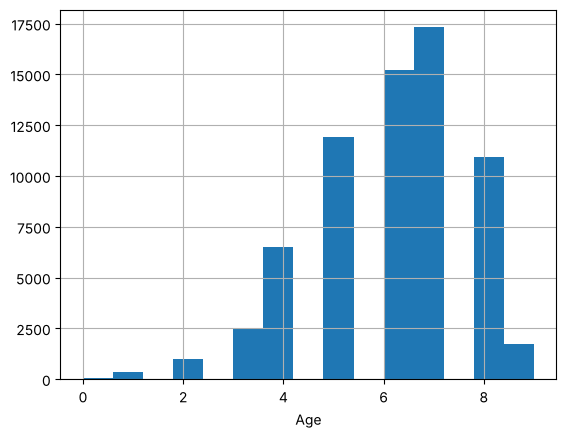

In [47]:
# Finding the distribution for the age of aptient
ax = data_hospital_unique['age'].hist(bins = 15, stacked = True)
ax.set(xlabel='Age')

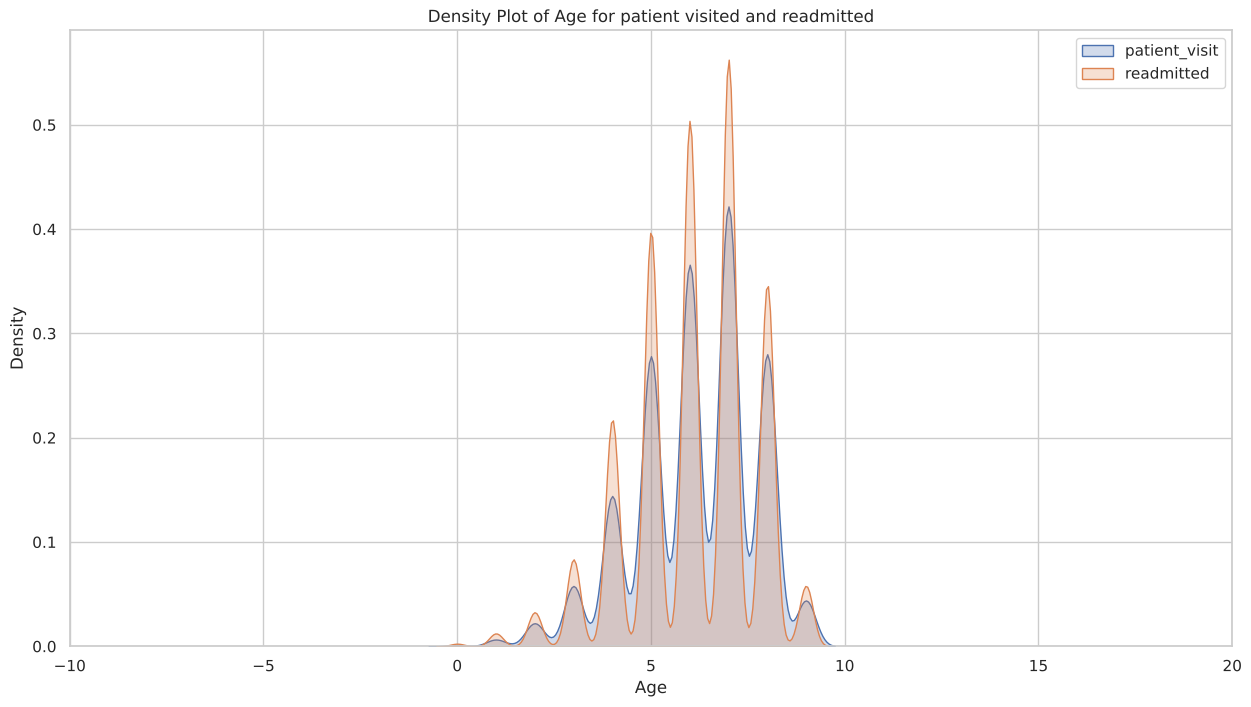

In [48]:
# Creating a density plot for the patient visited vs patient readmitted
from sklearn import preprocessing
plt.rc("font", size=14)
sb.set(style="white")
sb.set(style="whitegrid", color_codes=True)

plt.figure(figsize=(15,8))
ax = sb.kdeplot(data_hospital_unique["age"][data_hospital_unique.patient_visit == 1], fill=True)
sb.kdeplot(data_hospital_unique["age"][data_hospital_unique.patient_visit == 0], fill=True)
plt.legend(['patient_visit', 'readmitted'])
plt.title('Density Plot of Age for patient visited and readmitted')
ax.set(xlabel='Age')
plt.xlim(-10,20)
plt.show()

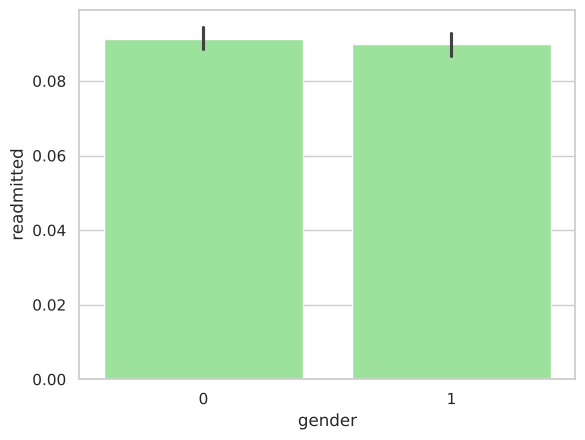

In [49]:
# Bar plot representing the distribution of gender
sb.barplot(x='gender', y='readmitted', data=data_hospital_unique, color="lightgreen")
plt.show()

In [50]:
data_hospital_unique.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'patient_visit', 'level1_diag1', 'level1_diag2', 'level1_diag3'],
      dtype='object')

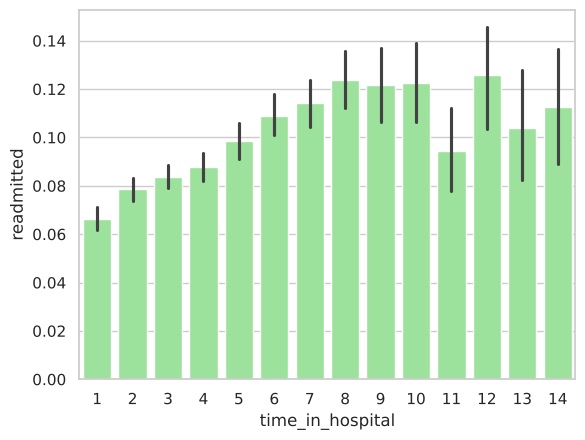

In [51]:
# Bar plot to show days spent by the patient in the hospital 
sb.barplot(x='time_in_hospital', y='readmitted', data=data_hospital_unique, color="lightgreen")
plt.show()

In [52]:
# sb.barplot(x= data_hospital_unique[['max_glu_serum', 'A1Cresult',
#        'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
#        'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
#        'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
#        'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin',
#        'metformin-pioglitazone', 'diabetesMed']], y=data_hospital_unique['readmitted'], color="lightgreen")
# plt.show()

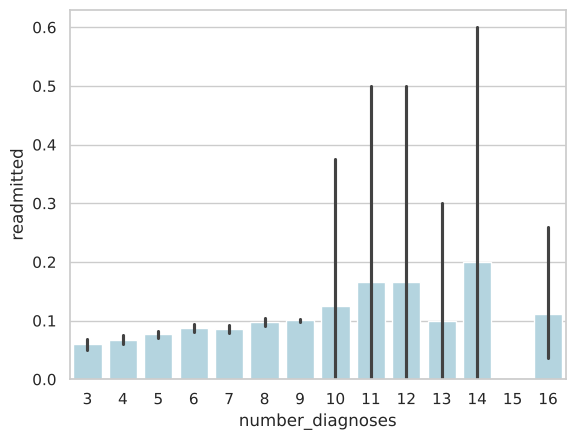

In [53]:
# Bar plot representing the number of diagnoses carried out for a patient and chances of getting readmitted
sb.barplot(x='number_diagnoses', y='readmitted', data=data_hospital_unique, color="lightblue")
plt.show()

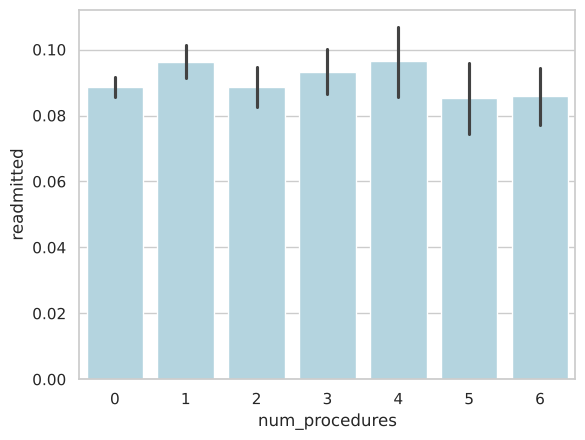

In [54]:
# Number of procedures for a patient that can get readmitted
sb.barplot(x='num_procedures', y='readmitted', data=data_hospital_unique, color="lightblue")
plt.show()

In [55]:
data_hospital_unique['readmitted']

1         0
2         0
3         0
4         0
5         0
         ..
101754    0
101755    0
101756    0
101758    0
101765    0
Name: readmitted, Length: 67580, dtype: int64

### Data Preparation

In [56]:
# # Divinding the dataset into features and label i.e. train_input repreneting all the features and train_output containing the readmitted values
train_input = data_hospital_unique.drop(['readmitted'], axis = 1)
train_output = data_hospital_unique['readmitted']

In [57]:
# Checking Multi-colinearity through VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(features):
    vif = pd.DataFrame()
    vif["Features"] = features.columns
    vif["VIF"] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]    
    return(vif)

In [58]:
vif = calculate_vif(train_input)
while vif['VIF'][vif['VIF'] > 10].any():
    remove = vif.sort_values('VIF',ascending=0)['Features'][:1]
    train_input.drop(remove,axis=1,inplace=True)
    vif = calculate_vif(train_input)

In [59]:
# VIF value demonstrating the possibility of multicollinarity
# where,
#       1 means no multicollinarity
#       1 - 5 means little multicollinarity
#       > 5 highly multicollinarity

vif.sort_values(['VIF'],ascending=0)

,Features,VIF
34,change,2.996556
30,insulin,2.723861
11,num_medications,1.728392
35,diabetesMed,1.723374
0,encounter_id,1.505526
8,time_in_hospital,1.447299
1,patient_nbr,1.431303
15,metformin,1.367285
5,admission_type_id,1.336937
9,num_lab_procedures,1.332292


In [60]:
# Removing multicollinarity values which are greater than 3
data_hospital_unique = data_hospital_unique.drop(columns=['A1Cresult','num_medications','diabetesMed','num_lab_procedures',
                                            'race','time_in_hospital', 'admission_source_id'], axis=1)

In [61]:
data_hospital_unique.shape

(67580, 34)

Text(0.5, 1.0, 'Distribution of Data')

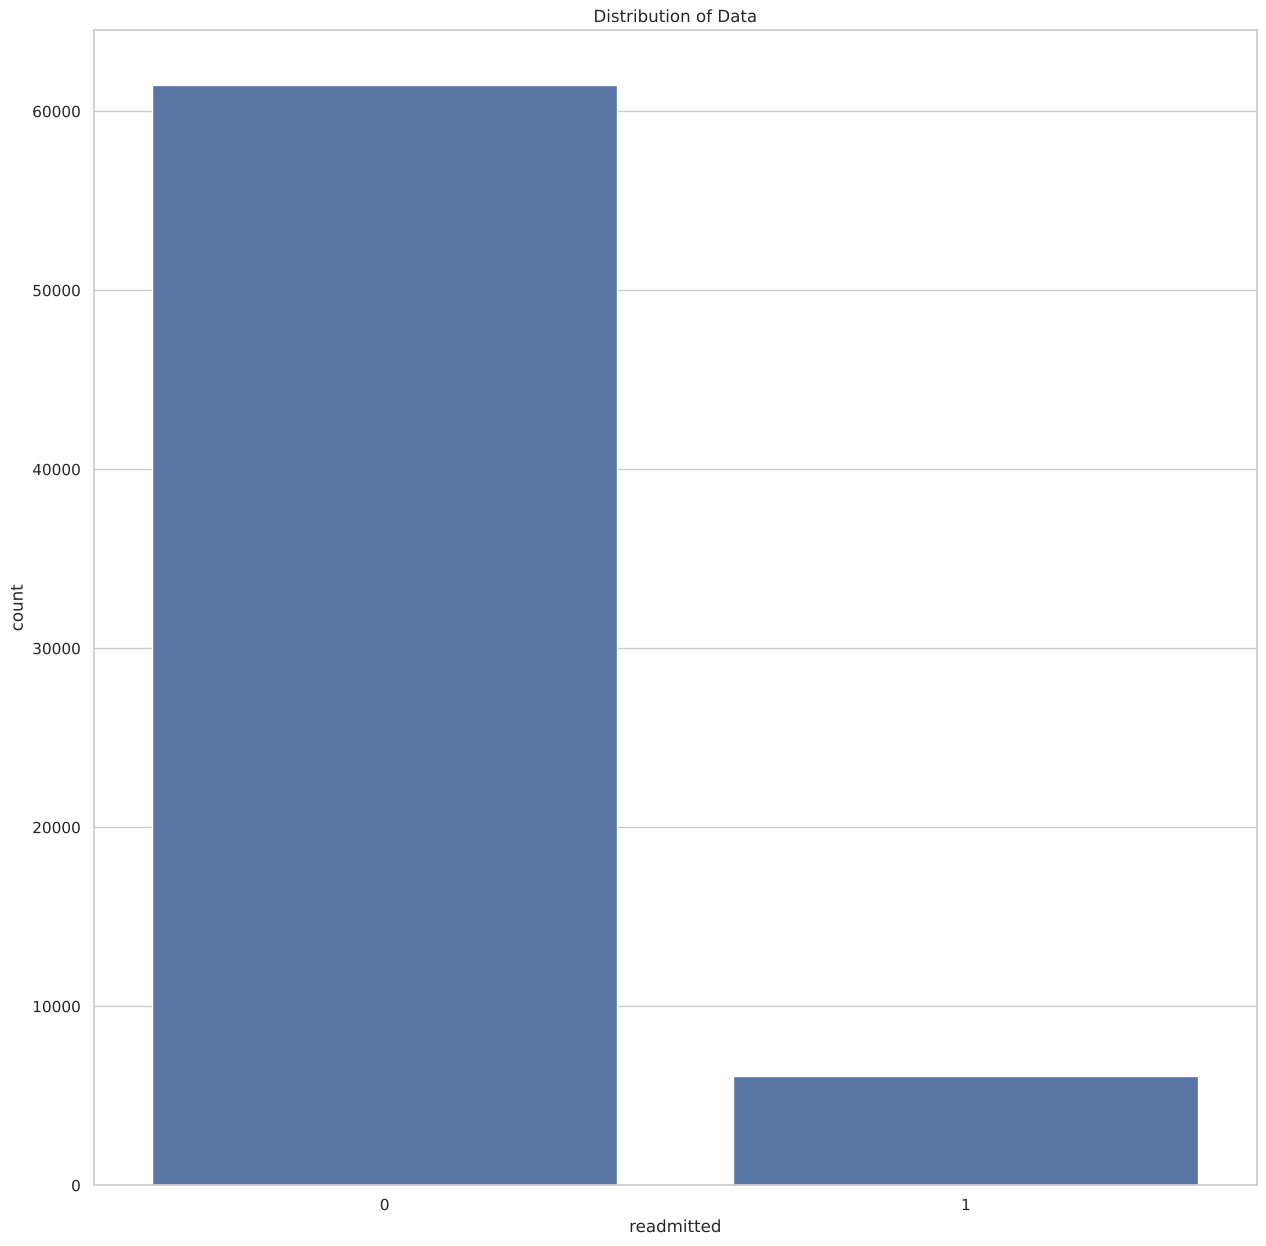

In [62]:
# Plotting the distrution of the readmitted patient
plt.figure(figsize=(15,15))

sb.countplot(x='readmitted',data=data_hospital_unique)

plt.title('Distribution of Data')

The above graph clearly shows that the data is not balanced and it need to be balanced in order to avoid biased outcome

In [63]:
# Divinding the dataset into features and label i.e. train_input repreneting all the features and train_output containing the readmitted values
train_input = data_hospital_unique.drop(['readmitted'], axis = 1)
train_output = data_hospital_unique['readmitted']

### Train/test split before any balancing

An earlier version of this notebook applied SMOTE to the whole dataset before splitting. That leaks synthetic copies of test patients into training and evaluates on an artificial 50/50 test set, which inflated accuracy to about 90%. Here the data is split first (stratified 80/20), identifier columns (encounter_id, patient_nbr) are removed, and the test set keeps the real readmission rate of about 9%.

In [64]:
from sklearn.model_selection import train_test_split
from collections import Counter

# identifiers carry no clinical meaning and can leak patient identity
X = data_hospital_unique.drop(columns=['readmitted', 'encounter_id', 'patient_nbr'])
y = data_hospital_unique['readmitted'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Training classes:', Counter(y_train))
print('Readmission rate - train: {:.1%}, test: {:.1%}'.format(y_train.mean(), y_test.mean()))

Train: (54064, 31)  Test: (13516, 31)
Training classes: Counter({0: 49161, 1: 4903})
Readmission rate - train: 9.1%, test: 9.1%


### Modeling

With a 9% positive rate, accuracy is misleading: predicting 'no readmission' for everyone scores about 91%. Imbalance is handled with class weights, and models are compared on ROC-AUC, PR-AUC, and recall and precision for the readmitted class.

In [65]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

def evaluate(name, p, rows):
    pred = (p >= 0.5).astype(int)
    rows.append({'Model': name,
                 'ROC-AUC': roc_auc_score(y_test, p),
                 'PR-AUC': average_precision_score(y_test, p),
                 'Recall (readmit)': recall_score(y_test, pred),
                 'Precision (readmit)': precision_score(y_test, pred, zero_division=0),
                 'F1 (readmit)': f1_score(y_test, pred),
                 'Accuracy': accuracy_score(y_test, pred)})

models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight='balanced', random_state=0),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight='balanced_subsample',
                                            n_jobs=-1, random_state=0),
}

rows, probs = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    probs[name] = m.predict_proba(X_test)[:, 1]
    evaluate(name, probs[name], rows)
results = pd.DataFrame(rows).set_index('Model').round(3)
print('PR-AUC of a random model = {:.3f}'.format(y_test.mean()))
results

PR-AUC of a random model = 0.091


,ROC-AUC,PR-AUC,Recall (readmit),Precision (readmit),F1 (readmit),Accuracy
Model,,,,,,
Decision Tree,0.620,0.135,0.488,0.134,0.210,0.667
Logistic Regression,0.592,0.122,0.537,0.116,0.191,0.587
Random Forest,0.630,0.150,0.396,0.146,0.213,0.735


### Does SMOTE help?

SMOTE creates synthetic patients by interpolating between real ones. Many features here are label-encoded categories (diagnosis group, discharge code, medication status), so interpolation produces values like 'diagnosis group 2.4' that never occur in real data. The model can learn to spot synthetic points instead of real risk. This cell tests SMOTE applied correctly, to the training split only.

In [66]:
from imblearn.over_sampling import SMOTE
X_sm, y_sm = SMOTE(random_state=20).fit_resample(X_train, y_train)
print('After SMOTE (training only):', Counter(y_sm))
rf_sm = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=0).fit(X_sm, y_sm)
cmp_rows = []
evaluate('Random Forest + class weights', probs['Random Forest'], cmp_rows)
evaluate('Random Forest + SMOTE (train only)', rf_sm.predict_proba(X_test)[:, 1], cmp_rows)
pd.DataFrame(cmp_rows).set_index('Model').round(3)

After SMOTE (training only): Counter({0: 49161, 1: 49161})


,ROC-AUC,PR-AUC,Recall (readmit),Precision (readmit),F1 (readmit),Accuracy
Model,,,,,,
Random Forest + class weights,0.630,0.150,0.396,0.146,0.213,0.735
Random Forest + SMOTE (train only),0.514,0.095,0.228,0.089,0.128,0.718


### Choosing a decision threshold

A care team can only follow up with a limited number of patients, so the threshold should be set by capacity, not left at 0.5. The table shows the trade-off for the best model by ROC-AUC.

In [67]:
best = results['ROC-AUC'].idxmax()
p = probs[best]
print('Best model by ROC-AUC:', best)
tbl = []
for q in [0.10, 0.20, 0.30, 0.50]:
    t = np.quantile(p, 1 - q)
    pred = (p >= t).astype(int)
    tbl.append({'Patients flagged (top share)': q, 'Threshold': round(t, 3),
                'Recall (readmit)': recall_score(y_test, pred),
                'Precision (readmit)': precision_score(y_test, pred, zero_division=0),
                'Lift vs random': precision_score(y_test, pred, zero_division=0) / y_test.mean()})
pd.DataFrame(tbl).round(3)

Best model by ROC-AUC: Random Forest


,Patients flagged (top share),Threshold,Recall (readmit),Precision (readmit),Lift vs random
0,0.1,0.568,0.195,0.177,1.949
1,0.2,0.520,0.338,0.153,1.692
2,0.3,0.478,0.462,0.140,1.542
3,0.5,0.416,0.669,0.121,1.338


[[10001  2289]
 [  811   415]]


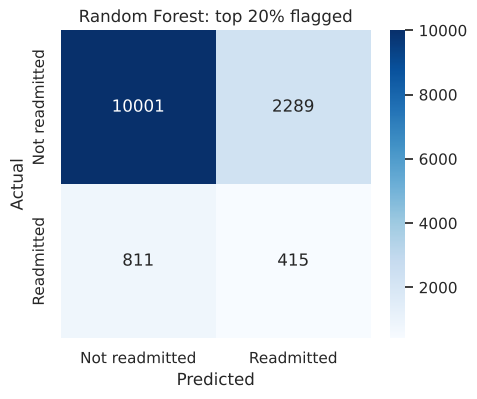

In [68]:
t = np.quantile(p, 0.80)  # flag the top 20% highest-risk patients
cm = confusion_matrix(y_test, (p >= t).astype(int))
print(cm)
plt.figure(figsize=(5,4))
sb.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Not readmitted', 'Readmitted'], yticklabels=['Not readmitted', 'Readmitted'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'{best}: top 20% flagged')
plt.show()

### What drives the predictions

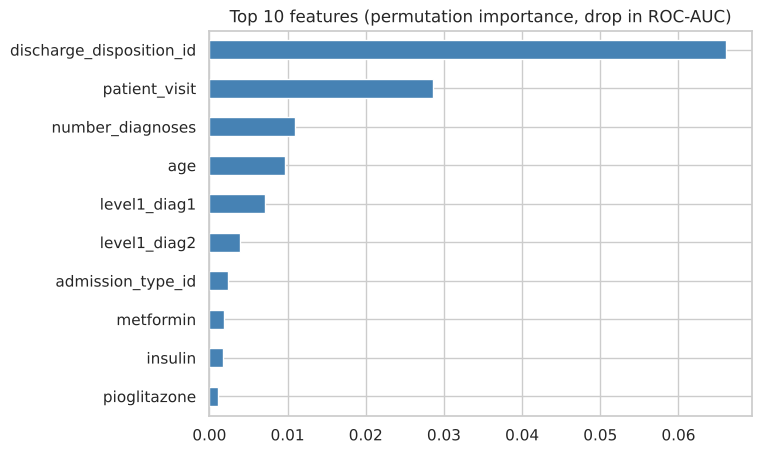

discharge_disposition_id    0.0661
patient_visit               0.0286
number_diagnoses            0.0109
age                         0.0097
level1_diag1                0.0071
level1_diag2                0.0040
admission_type_id           0.0023
metformin                   0.0018
insulin                     0.0018
pioglitazone                0.0011
dtype: float64

In [69]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(models[best], X_test, y_test, scoring='roc_auc',
                            n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(7,5))
imp[::-1].plot(kind='barh', color='steelblue')
plt.title('Top 10 features (permutation importance, drop in ROC-AUC)')
plt.show()
imp.round(4)

### Conclusions

- Random Forest with class weights is the best model: **ROC-AUC 0.63** and **PR-AUC 0.15** on a test set with the real 9.1% readmission rate (a random model's PR-AUC is 0.09).
- Flagging the **top 20%** highest-risk patients catches **34%** of 30-day readmissions at **1.7x** the base rate; the top 10% gives about **2x** lift.
- Strongest drivers: discharge disposition, prior hospital visits (outpatient + emergency + inpatient), number of diagnoses and age.
- SMOTE hurt here (ROC-AUC 0.51 vs 0.63) because interpolating label-encoded categories creates unrealistic values; class weights work better.
- An earlier version reported about 90% accuracy because SMOTE was applied before the train/test split. Those results were not valid and this version replaces them.
- Readmission is hard to predict from administrative data alone. Next steps: one-hot encoding, gradient boosting (XGBoost/LightGBM) with tuning, using all encounters with group-aware cross-validation by patient, and SHAP explanations.